In [ ]:
# Install required libraries (run once)
!pip install torch torchvision scipy scikit-learn matplotlib pandas numpy soundfile tqdm seaborn --quiet

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import librosa
from scipy import signal
from scipy.io import wavfile
import soundfile as sf
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score
from tqdm import tqdm
import warnings
import math
warnings.filterwarnings('ignore')

# PyTorch imports
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import torch.nn.functional as F

# Set random seeds for reproducibility
np.random.seed(42)
torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed(42)

# Set device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

print(f"PyTorch version: {torch.__version__}")
print(f"Device: {device}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")


PyTorch version: 2.9.0+cu126
Device: cuda
GPU: Tesla T4


In [ ]:
!pip install seaborn

In [ ]:
!sudo apt-get install unrar
!unrar x "/content/drive/My Drive/wmms_audio.rar" "/content/wmms_audio/"

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
unrar is already the newest version (1:6.1.5-1ubuntu0.1).
0 upgraded, 0 newly installed, 0 to remove and 41 not upgraded.

UNRAR 6.11 beta 1 freeware      Copyright (c) 1993-2022 Alexander Roshal


Extracting from /content/drive/My Drive/wmms_audio.rar

Creating    /content/wmms_audio                                       OK
Creating    /content/wmms_audio/wmms_audio                            OK
Extracting  /content/wmms_audio/wmms_audio/clip_00000.wav                  0%  OK 
Extracting  /content/wmms_audio/wmms_audio/clip_00001.wav                  0%  OK 
Extracting  /content/wmms_audio/wmms_audio/clip_00002.wav                  0%  OK 
Extracting  /content/wmms_audio/wmms_audio/clip_00003.wav                  0%  OK 
Extracting  /content/wmms_audio/wmms_audio/clip_00004.wav                  0%  OK 
Extracting  /content/wmms_audio/wmms_audio/

In [ ]:
from google.colab import drive

In [ ]:
drive.mount('/content/drive/')

Mounted at /content/drive/


In [ ]:
path = 'drive/My Drive/wmms_labels.csv'

In [ ]:
# Dataset paths
AUDIO_DIR = "/content/wmms_audio/wmms_audio"
LABELS_CSV = 'wmms_labels.csv'
# Audio processing parameters
SAMPLE_RATE = 10000
DURATION = 5
N_FFT = 2048
HOP_LENGTH = 256
N_FREQ_BINS = 64
# Training parameters
BATCH_SIZE = 16
EPOCHS = 80
LEARNING_RATE = 0.001
VALIDATION_SPLIT = 0.2
TEST_SIZE = 0.2

print("Configuration set successfully")

Configuration set successfully


In [ ]:
# Loading the CSV labels from this dataset
df = pd.read_csv(path)

print(f"CSV Shape: {df.shape}")
print(f"\nColumns: {df.columns.tolist()}")
print("\nFirst 10 rows:")
display(df.head(10))

CSV Shape: (1357, 4)

Columns: ['file', 'species', 'label_id', 'duration_sec']

First 10 rows:


,file,species,label_id,duration_sec
0,clip_00000.wav,Spinner_Dolphin,26,NaN
1,clip_00001.wav,Bearded_Seal,1,NaN
2,clip_00002.wav,Weddell_Seal,29,NaN
3,clip_00003.wav,Harp_Seal,11,NaN
4,clip_00004.wav,False_Killer_Whale,7,NaN
5,clip_00005.wav,Frasers_Dolphin,9,NaN
6,clip_00006.wav,Long-Finned_Pilot_Whale,15,NaN
7,clip_00007.wav,"Beluga,_White_Whale",2,NaN
8,clip_00008.wav,Atlantic_Spotted_Dolphin,0,NaN
9,clip_00009.wav,Spinner_Dolphin,26,NaN


In [ ]:
# Identify filename and label columns
print("Available columns:")
for i, col in enumerate(df.columns):
    print(f"  {i}: {col}")

# Auto-detect columns (adjust if needed)
filename_col = 'file' if 'file' in df.columns else df.columns[0]
label_col = 'species' if 'species' in df.columns else df.columns[1]

print(f"\nUsing '{filename_col}' as filename column")
print(f"Using '{label_col}' as label column")

Available columns:
  0: file
  1: species
  2: label_id
  3: duration_sec

Using 'file' as filename column
Using 'species' as label column



Number of classes: 32

Class distribution:
species
Spinner_Dolphin                     91
Frasers_Dolphin                     69
Striped_Dolphin                     65
Sperm_Whale                         60
Long-Finned_Pilot_Whale             56
Grampus,_Rissos_Dolphin             54
Pantropical_Spotted_Dolphin         53
Short-Finned_Pacific_Pilot_Whale    53
Humpback_Whale                      51
Clymene_Dolphin                     50
Melon_Headed_Whale                  50
Bowhead_Whale                       48
False_Killer_Whale                  47
White-beaked_Dolphin                46
Atlantic_Spotted_Dolphin            46
White-sided_Dolphin                 44
Northern_Right_Whale                43
Common_Dolphin                      42
Rough-Toothed_Dolphin               40
Fin,_Finback_Whale                  40
Beluga,_White_Whale                 40
Narwhal                             40
Ross_Seal                           40
Harp_Seal                           38
Bearded_Seal

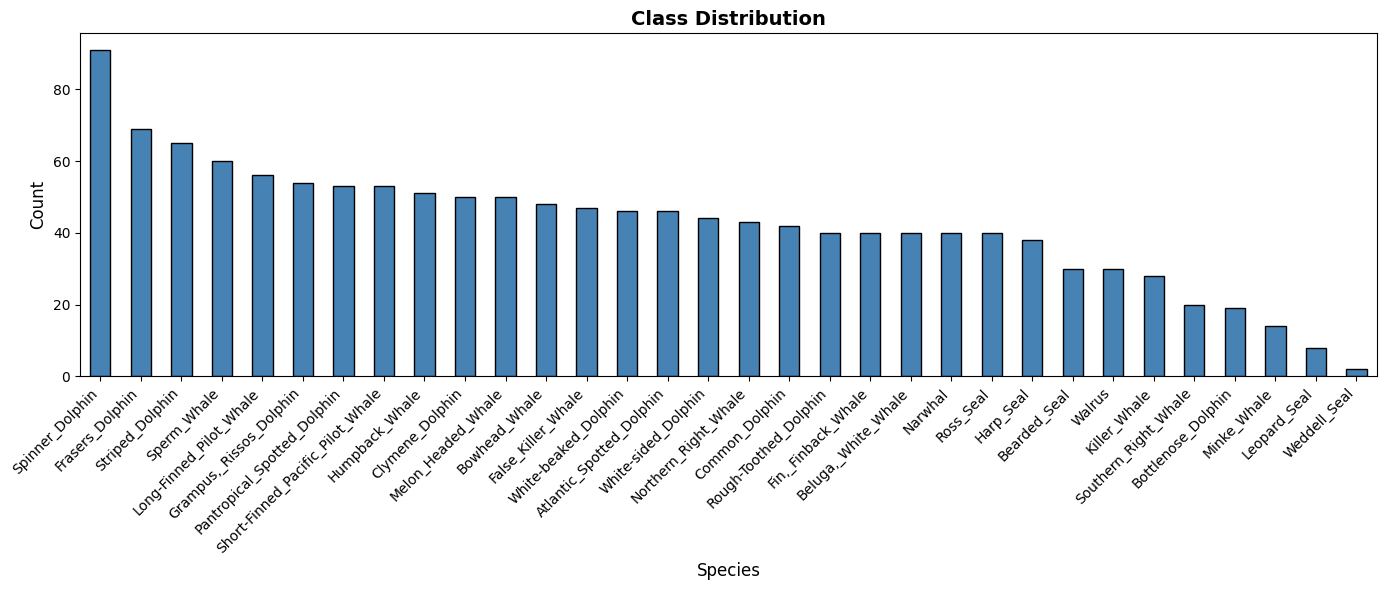


Min samples per class: 2
Max samples per class: 91
Imbalance ratio: 45.50


In [ ]:
# This part shows the Class distribution
class_counts = df[label_col].value_counts()
print(f"\nNumber of classes: {len(class_counts)}")
print(f"\nClass distribution:")
print(class_counts)

# Plotting the class distribution
plt.figure(figsize=(14, 6))
class_counts.plot(kind='bar', color='steelblue', edgecolor='black')
plt.title('Class Distribution', fontsize=14, fontweight='bold')
plt.xlabel('Species', fontsize=12)
plt.ylabel('Count', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

# Check the class imbalance
min_samples = class_counts.min()
max_samples = class_counts.max()
imbalance_ratio = max_samples / min_samples

print(f"\nMin samples per class: {min_samples}")
print(f"Max samples per class: {max_samples}")
print(f"Imbalance ratio: {imbalance_ratio:.2f}")

In [ ]:
def load_audio(audio_path = AUDIO_DIR, target_sr=SAMPLE_RATE, duration=DURATION):
    """
    Load audio file and resample if necessary

    Args:
        audio_path: Path to audio file
        target_sr: Target sample rate
        duration: Duration in seconds

    Returns:
        audio: Audio signal as numpy array
        sr: Sample rate
    """
    try:
        # Loading audio using the soundfile
        audio, sr = sf.read(audio_path)

        # Converting stereo to mono if needed
        if len(audio.shape) > 1:
            audio = np.mean(audio, axis=1)

        # Resample if necessary
        if sr != target_sr:
            # Calculate number of samples for target sample rate
            num_samples = int(len(audio) * target_sr / sr)
            audio = signal.resample(audio, num_samples)
            sr = target_sr

        # Pad or trim to fixed length
        target_length = target_sr * duration
        if len(audio) < target_length:
            audio = np.pad(audio, (0, target_length - len(audio)), mode='constant')
        else:
            audio = audio[:target_length]

        return audio, sr

    except Exception as e:
        print(f"Error loading {audio_path}: {str(e)}")
        return None, None


def audio_to_spectrogram(audio_path = AUDIO_DIR, sample_rate=SAMPLE_RATE, duration=DURATION,
                         n_fft=N_FFT, hop_length=HOP_LENGTH, n_freq_bins=N_FREQ_BINS):
    """
    Convert audio file to spectrogram using scipy.signal.spectrogram

    Args:
        audio_path: Path to audio file
        sample_rate: Target sample rate
        duration: Audio duration in seconds
        n_fft: FFT window size
        hop_length: Hop length between windows
        n_freq_bins: Number of frequency bins to keep

    Returns:
        Normalized spectrogram as numpy array
    """
    try:
        # Loading the audio
        audio, sr = load_audio(audio_path, sample_rate, duration)

        if audio is None:
            return None

        # Calculating the noverlap from hop_length
        noverlap = n_fft - hop_length

        # Computing the spectrogram by using scipy
        frequencies, times, Sxx = signal.spectrogram(
            audio,
            fs=sr,
            window='hann',
            nperseg=n_fft,
            noverlap=noverlap,
            nfft=n_fft,
            scaling='density',
            mode='magnitude'
        )

        # Keep only the first n_freq_bins frequency bins
        Sxx = Sxx[:n_freq_bins, :]

        # Convert to log scale (dB) - add small epsilon to avoid log(0)
        Sxx_db = 10 * np.log10(Sxx + 1e-10)

        # Normalize to [0, 1]
        Sxx_norm = (Sxx_db - Sxx_db.min()) / (Sxx_db.max() - Sxx_db.min() + 1e-8)

        return Sxx_norm

    except Exception as e:
        print(f"Error processing {audio_path}: {str(e)}")
        return None

print("Audio processing functions defined (using scipy spectrogram)!")

Audio processing functions defined (using scipy spectrogram)!


In [ ]:
print("Files in current directory:", os.listdir('.'))

Files in current directory: ['.config', 'whale_transformer_classifier.pth', 'drive', 'label_encoder.pkl', 'whale_transformer_classifier_full.pth', 'whale_transformer_training_history.csv', 'wmms_audio', 'best_whale_transformer.pth', 'sample_data']


In [ ]:
print("Files one level up:", os.listdir('.'))

Files one level up: ['.config', 'whale_transformer_classifier.pth', 'drive', 'label_encoder.pkl', 'whale_transformer_classifier_full.pth', 'whale_transformer_training_history.csv', 'wmms_audio', 'best_whale_transformer.pth', 'sample_data']


Example filenames from df: 0    clip_00000.wav
1    clip_00001.wav
2    clip_00002.wav
3    clip_00003.wav
4    clip_00004.wav
Name: file, dtype: object
Files actually in AUDIO_DIR: ['clip_00533.wav', 'clip_01268.wav', 'clip_00879.wav', 'clip_00618.wav', 'clip_00089.wav', 'clip_00977.wav', 'clip_00255.wav', 'clip_00323.wav', 'clip_00281.wav', 'clip_00248.wav']
File FOUND: /content/wmms_audio/wmms_audio/clip_00008.wav
File FOUND: /content/wmms_audio/wmms_audio/clip_00001.wav
File FOUND: /content/wmms_audio/wmms_audio/clip_00007.wav
File FOUND: /content/wmms_audio/wmms_audio/clip_00039.wav
File FOUND: /content/wmms_audio/wmms_audio/clip_00018.wav
File FOUND: /content/wmms_audio/wmms_audio/clip_00136.wav


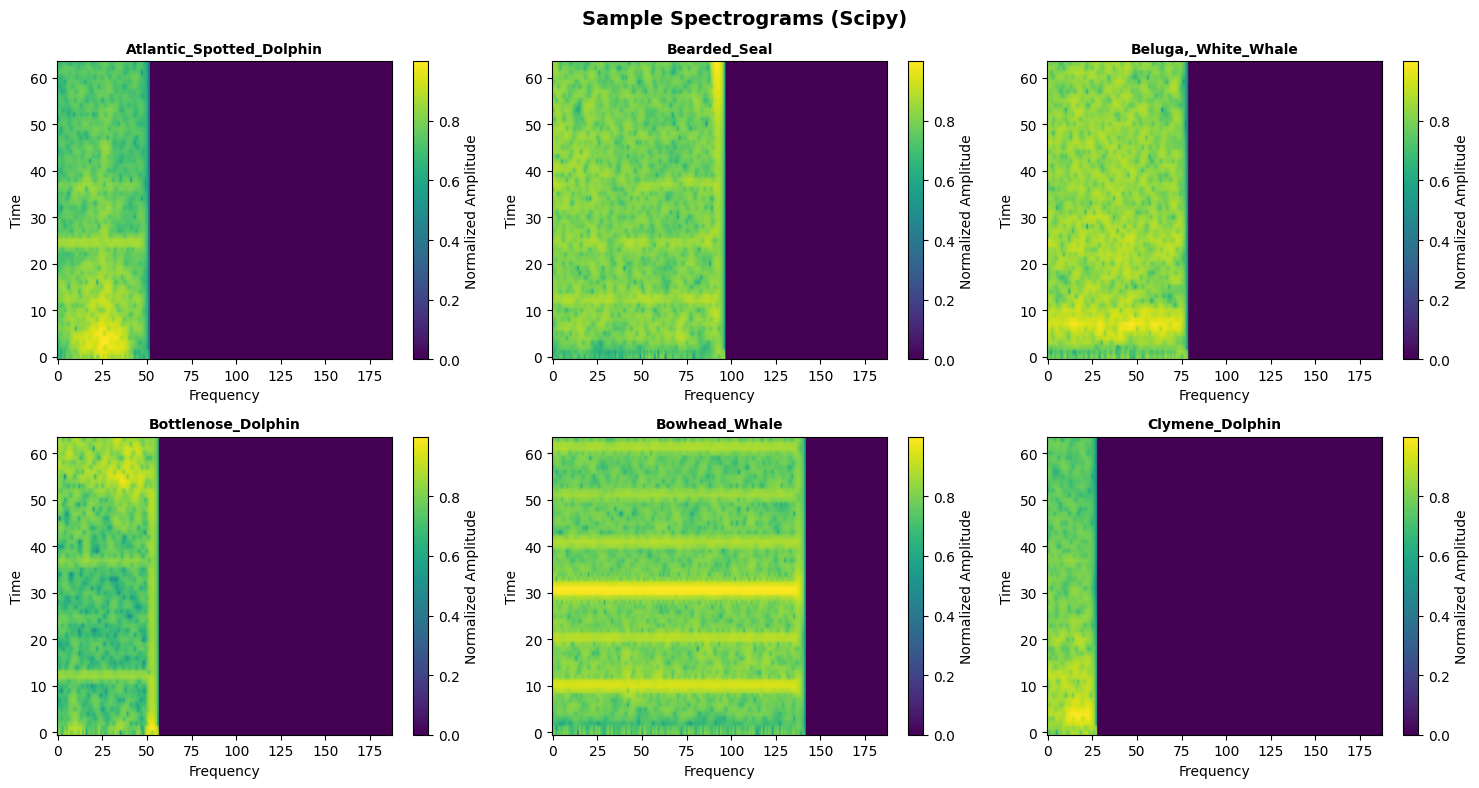

In [ ]:
# Get sample files for visualization
sample_files = df.groupby(label_col).first().reset_index()
num_samples = min(6, len(sample_files))

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

print("Example filenames from df:", df[filename_col].head())
print("Files actually in AUDIO_DIR:", os.listdir(AUDIO_DIR)[:10])

for i, (idx, row) in enumerate(sample_files.head(num_samples).iterrows()):
    filename = row[filename_col]
    label = row[label_col]
    audio_path = os.path.join(AUDIO_DIR, filename)



    if not os.path.exists(audio_path):
            print("File NOT FOUND:", audio_path)
            continue
    else:
            print("File FOUND:", audio_path)

    if os.path.exists(audio_path):
        spec = audio_to_spectrogram(audio_path)
        if spec is not None:
            im = axes[i].imshow(spec, aspect='auto', origin='lower', cmap='viridis')
            axes[i].set_title(f'{label}', fontsize=10, fontweight='bold')
            axes[i].set_xlabel('Frequency')
            axes[i].set_ylabel('Time')
            plt.colorbar(im, ax=axes[i], label='Normalized Amplitude')
plt.suptitle('Sample Spectrograms (Scipy)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

In [ ]:
# Loading all audio files and convert to spectrograms
print("Loading and processing audio files...")
print("This may take a few minutes depending on dataset size.\n")

X = []
y = []
failed_files = []

for idx, row in tqdm(df.iterrows(), total=len(df), desc="Processing audio"):
    filename = row[filename_col]
    label = row[label_col]

    # Trying to find the audio file
    audio_path = os.path.join(AUDIO_DIR, filename)

    if not os.path.exists(audio_path):
        # Trying different extensions
        for ext in ['.wav', '.mp3', '.flac', '.ogg']:
            base_name = os.path.splitext(filename)[0]
            audio_path = os.path.join(AUDIO_DIR, base_name + ext)
            if os.path.exists(audio_path):
                break

    if not os.path.exists(audio_path):
        failed_files.append(filename)
        continue

    # Conversion to the spectrogram
    spec = audio_to_spectrogram(audio_path)

    if spec is not None:
        X.append(spec)
        y.append(label)

if failed_files:
    print(f"\n Warning: Could not find {len(failed_files)} audio files")

# Conversion to numpy arrays
X = np.array(X)
y = np.array(y)

# Addding the channel dimension for CNN (batch, channel, height, width)
if X.size > 0: # Add a check to ensure X is not empty
    X = X[:, np.newaxis, :, :]  # PyTorch expects (N, C, H, W)
else:
    print("Warning: X is empty, skipping channel dimension addition.")

print(f"\n{'='*60}")
print("Data Preparation Complete!")
print(f"{'='*60}")
print(f"Total samples loaded: {len(X)}")
print(f"Spectrogram shape: {X.shape}")
print(f"Input shape per sample: {X.shape[1:]}")

Loading and processing audio files...
This may take a few minutes depending on dataset size.



Processing audio: 100%|██████████| 1357/1357 [01:58<00:00, 11.43it/s]


Data Preparation Complete!
Total samples loaded: 1357
Spectrogram shape: (1357, 1, 64, 188)
Input shape per sample: (1, 64, 188)


In [ ]:
# Labels for the Encoder
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

print(f"Number of classes: {len(label_encoder.classes_)}")
print(f"Classes: {label_encoder.classes_}")

Number of classes: 32
Classes: ['Atlantic_Spotted_Dolphin' 'Bearded_Seal' 'Beluga,_White_Whale'
 'Bottlenose_Dolphin' 'Bowhead_Whale' 'Clymene_Dolphin' 'Common_Dolphin'
 'False_Killer_Whale' 'Fin,_Finback_Whale' 'Frasers_Dolphin'
 'Grampus,_Rissos_Dolphin' 'Harp_Seal' 'Humpback_Whale' 'Killer_Whale'
 'Leopard_Seal' 'Long-Finned_Pilot_Whale' 'Melon_Headed_Whale'
 'Minke_Whale' 'Narwhal' 'Northern_Right_Whale'
 'Pantropical_Spotted_Dolphin' 'Ross_Seal' 'Rough-Toothed_Dolphin'
 'Short-Finned_Pacific_Pilot_Whale' 'Southern_Right_Whale' 'Sperm_Whale'
 'Spinner_Dolphin' 'Striped_Dolphin' 'Walrus' 'Weddell_Seal'
 'White-beaked_Dolphin' 'White-sided_Dolphin']


In [ ]:
# Splitting the data into training and testing sets
if len(X) == 0:
    print("Error: No samples loaded. Please ensure audio files are in the specified directory and can be processed.")
else:
  X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded,
    test_size=TEST_SIZE,
    random_state=42,
    stratify=y_encoded
)

# Further splitting the  data into training and validation sets
X_train, X_val, y_train, y_val = train_test_split(
    X_train, y_train,
    test_size=VALIDATION_SPLIT,
    random_state=42,
    stratify=y_train
)

print(f"Training set: {len(X_train)} samples")
print(f"Validation set: {len(X_val)} samples")
print(f"Test set: {len(X_test)} samples")
print(f"\nTraining data shape: {X_train.shape}")

Training set: 868 samples
Validation set: 217 samples
Test set: 272 samples

Training data shape: (868, 1, 64, 188)


In [ ]:
class WhaleAudioDataset(Dataset):
    """Custom Dataset for whale audio spectrograms"""

    def __init__(self, X, y, transform=None):
        self.X = torch.FloatTensor(X)
        self.y = torch.LongTensor(y)
        self.transform = transform

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        x = self.X[idx]
        y = self.y[idx]

        if self.transform:
            x = self.transform(x)

        return x, y

# Creating the datasets
train_dataset = WhaleAudioDataset(X_train, y_train)
val_dataset = WhaleAudioDataset(X_val, y_val)
test_dataset = WhaleAudioDataset(X_test, y_test)

# Creating the dataloaders
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

print(f"Train batches: {len(train_loader)}")
print(f"Validation batches: {len(val_loader)}")
print(f"Test batches: {len(test_loader)}")

Train batches: 55
Validation batches: 14
Test batches: 17


In [ ]:
# Spectrogram + DNN Model
class WhaleDNN(nn.Module):
   """DNN model for whale audio classification"""

   def __init__(self, num_classes, input_size=N_FREQ_BINS, hidden_size=256):
        super(WhaleDNN, self).__init__()
        self.model = nn.Sequential(
            nn.Flatten(),
            nn.Linear(input_size, hidden_size),
            nn.ReLU(),
            nn.Linear(input_size, hidden_size),
            nn.ReLU(),
            nn.Linear(input_size, hidden_size),
            nn.Dropout(0.5)
            )
        def forward(self, x):
            return self.model(x)

print("DNN Model defined!")

DNN Model defined!


In [ ]:
# Spectrogram + CNN Model
class WhaleCNN(nn.Module):
    """CNN model for whale audio classification"""

    def __init__(self, num_classes, input_height=N_FREQ_BINS, input_width=None):
        super(WhaleCNN, self).__init__()

        # First Convolutional Block
        self.conv1a = nn.Conv2d(1, 16, kernel_size=3, padding=1)
        self.bn1a = nn.BatchNorm2d(16)
        self.conv1b = nn.Conv2d(16, 16, kernel_size=3, padding=1)
        self.bn1b = nn.BatchNorm2d(16)
        self.pool1 = nn.MaxPool2d(2, 2)
        self.dropout1 = nn.Dropout(0.25)

        # Second Convolutional Block
        self.conv2a = nn.Conv2d(16, 32, kernel_size=3, padding=1)
        self.bn2a = nn.BatchNorm2d(32)
        self.conv2b = nn.Conv2d(32, 32, kernel_size=3, padding=1)
        self.bn2b = nn.BatchNorm2d(32)
        self.pool2 = nn.MaxPool2d(2, 2)
        self.dropout2 = nn.Dropout(0.25)

        # Third Convolutional Block
        self.conv3a = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.bn3a = nn.BatchNorm2d(64)
        self.conv3b = nn.Conv2d(64, 64, kernel_size=3, padding=1)
        self.bn3b = nn.BatchNorm2d(64)
        self.pool3 = nn.MaxPool2d(2, 2)
        self.dropout3 = nn.Dropout(0.25)

        # Fourth Convolutional Block
        self.conv4 = nn.Conv2d(64, 128, kernel_size=3, padding=1)
        self.bn4 = nn.BatchNorm2d(128)
        self.pool4 = nn.MaxPool2d(2, 2)
        self.dropout4 = nn.Dropout(0.25)

        # Adaptive pooling to handle variable input sizes
        self.adaptive_pool = nn.AdaptiveAvgPool2d((4, 8))

        # Fully Connected Layers
        self.flatten_size = 128 * 4 * 8
        self.fc1 = nn.Linear(self.flatten_size,256)
        self.bn_fc1 = nn.BatchNorm1d(256)
        self.dropout_fc1 = nn.Dropout(0.5)

        self.fc2 = nn.Linear(256, 128)
        self.bn_fc2 = nn.BatchNorm1d(128)
        self.dropout_fc2 = nn.Dropout(0.5)

        self.fc3 = nn.Linear(128, num_classes)

    def forward(self, x):
        # Block 1
        x = F.relu(self.bn1a(self.conv1a(x)))
        x = F.relu(self.bn1b(self.conv1b(x)))
        x = self.pool1(x)
        x = self.dropout1(x)

        # Block 2
        x = F.relu(self.bn2a(self.conv2a(x)))
        x = F.relu(self.bn2b(self.conv2b(x)))
        x = self.pool2(x)
        x = self.dropout2(x)

        # Block 3
        x = F.relu(self.bn3a(self.conv3a(x)))
        x = F.relu(self.bn3b(self.conv3b(x)))
        x = self.pool3(x)
        x = self.dropout3(x)

        # Block 4
        x = F.relu(self.bn4(self.conv4(x)))
        x = self.pool4(x)
        x = self.dropout4(x)

        # Adaptive pooling
        x = self.adaptive_pool(x)

        # Flatten
        x = x.view(x.size(0), -1)

        # Fully connected
        x = F.relu(self.bn_fc1(self.fc1(x)))
        x = self.dropout_fc1(x)

        x = F.relu(self.bn_fc2(self.fc2(x)))
        x = self.dropout_fc2(x)

        x = self.fc3(x)

        return x

print("CNN Model defined!")

CNN Model defined!


In [ ]:
# Spectrogram + RNN Model
class WhaleRNN(nn.Module):
    """RNN model for whale audio classification"""

    def __init__(self, num_classes, input_size=N_FREQ_BINS, hidden_size=256, num_layers=2, bidirectional=True, dropout=0.3):
        super(WhaleRNN, self).__init__()

        self.hidden_size = hidden_size
        self.num_layers = num_layers
        self.bidirectional = bidirectional
        self.num_directions = 2 if bidirectional else 1

        self.rnn = nn.RNN(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            bidirectional=bidirectional,
            dropout=dropout if num_layers > 1 else 0
        )
        #Dropout
        self.dropout = nn.Dropout(dropout)

        # Fully connected layers
        self.fc1 = nn.Linear(hidden_size * self.num_directions, num_classes) # Corrected output to num_classes

    def forward(self, x):
        # Input shape: (batch, 1, freq_bins, time_steps)
        # Squeeze channel dimension and permute to (batch, time_steps, freq_bins)
        x = x.squeeze(1) # (batch, freq_bins, time_steps)
        x = x.permute(0, 2, 1) # (batch, time_steps, freq_bins)

        rnn_out, _ = self.rnn(x)
        last_out = rnn_out[:, -1, :]
        last_out = self.dropout(last_out)
        out = self.fc1(last_out)
        return out # Corrected return value

print("RNN Model defined!")

RNN Model defined!


In [ ]:
# Spectrogram + LSTM Model
class WhaleLSTM(nn.Module):
    """LSTM model for whale audio classification. Treats spectrogram as a sequence of frequency vectors over time"""

    def __init__(self, num_classes, input_size=N_FREQ_BINS, hidden_size=256,
                 num_layers=2, bidirectional=True, dropout=0.3):
        super(WhaleLSTM, self).__init__()

        self.hidden_size = hidden_size
        self.num_layers = num_layers
        self.bidirectional = bidirectional
        self.num_directions = 2 if bidirectional else 1

        # LSTM layers
        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            bidirectional=bidirectional,
            dropout=dropout if num_layers > 1 else 0
        )

        # Layer normalization
        self.layer_norm = nn.LayerNorm(hidden_size * self.num_directions)

        # Attention mechanism
        self.attention = nn.Sequential(
            nn.Linear(hidden_size * self.num_directions, 128),
            nn.Tanh(),
            nn.Linear(128, 1)
        )

        # Fully connected layers
        self.fc1 = nn.Linear(hidden_size * self.num_directions, 256)
        self.bn1 = nn.BatchNorm1d(256)
        self.dropout1 = nn.Dropout(0.5)

        self.fc2 = nn.Linear(256, 128)
        self.bn2 = nn.BatchNorm1d(128)
        self.dropout2 = nn.Dropout(0.5)

        self.fc3 = nn.Linear(128, num_classes)

    def forward(self, x):
        # Input shape: (batch, 1, freq_bins, time_steps)
        # Remove channel dimension and transpose to (batch, time_steps, freq_bins)
        x = x.squeeze(1)  # (batch, freq_bins, time_steps)
        x = x.permute(0, 2, 1)  # (batch, time_steps, freq_bins)

        # LSTM forward
        lstm_out, (hidden, cell) = self.lstm(x)
        # lstm_out shape: (batch, time_steps, hidden_size * num_directions)

        # Apply layer normalization
        lstm_out = self.layer_norm(lstm_out)

        # Attention mechanism
        attention_weights = self.attention(lstm_out)  # (batch, time_steps, 1)
        attention_weights = F.softmax(attention_weights, dim=1)

        # Weighted sum of LSTM outputs
        context = torch.sum(attention_weights * lstm_out, dim=1)  # (batch, hidden_size * num_directions)

        # Fully connected layers
        x = F.relu(self.bn1(self.fc1(context)))
        x = self.dropout1(x)

        x = F.relu(self.bn2(self.fc2(x)))
        x = self.dropout2(x)

        x = self.fc3(x)

        return x

print("LSTM Model defined!")

LSTM Model defined!


In [ ]:
# Spectrogram + Transformer Model
class PositionalEncoding(nn.Module):
    """Positional encoding for Transformer"""

    def __init__(self, d_model, max_len=5000, dropout=0.1):
        super(PositionalEncoding, self).__init__()
        self.dropout = nn.Dropout(p=dropout)

        # Create positional encoding
        pe = torch.zeros(max_len, d_model)
        position = torch.arange(0, max_len, dtype=torch.float).unsqueeze(1)
        div_term = torch.exp(torch.arange(0, d_model, 2).float() * (-math.log(10000.0) / d_model))

        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)
        pe = pe.unsqueeze(0)  # (1, max_len, d_model)

        self.register_buffer('pe', pe)

    def forward(self, x):
        # x shape: (batch, seq_len, d_model)
        x = x + self.pe[:, :x.size(1), :]
        return self.dropout(x)


class WhaleTransformer(nn.Module):
    """
    Transformer model for whale audio classification
    Treats spectrogram as a sequence of frequency vectors over time
    """

    def __init__(self, num_classes, input_size=N_FREQ_BINS, d_model=256,
                 nhead=8, num_encoder_layers=4, dim_feedforward=512, dropout=0.1):
        super(WhaleTransformer, self).__init__()

        self.d_model = d_model

        # Input projection
        self.input_projection = nn.Linear(input_size, d_model)

        # Positional encoding
        self.pos_encoder = PositionalEncoding(d_model, dropout=dropout)

        # Transformer encoder
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=nhead,
            dim_feedforward=dim_feedforward,
            dropout=dropout,
            batch_first=True
        )
        self.transformer_encoder = nn.TransformerEncoder(
            encoder_layer,
            num_layers=num_encoder_layers
        )

        # Classification token (learnable)
        self.cls_token = nn.Parameter(torch.randn(1, 1, d_model))

        # Layer normalization
        self.layer_norm = nn.LayerNorm(d_model)

        # Classification head
        self.classifier = nn.Sequential(
            nn.Linear(d_model, 256),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        # Input shape: (batch, 1, freq_bins, time_steps)
        # Remove channel dimension and transpose to (batch, time_steps, freq_bins)
        x = x.squeeze(1)  # (batch, freq_bins, time_steps)
        x = x.permute(0, 2, 1)  # (batch, time_steps, freq_bins)

        batch_size = x.size(0)

        # Project input to d_model dimensions
        x = self.input_projection(x)  # (batch, time_steps, d_model)

        # Add classification token at the beginning
        cls_tokens = self.cls_token.expand(batch_size, -1, -1)  # (batch, 1, d_model)
        x = torch.cat([cls_tokens, x], dim=1)  # (batch, time_steps + 1, d_model)

        # Add positional encoding
        x = self.pos_encoder(x)

        # Transformer encoder
        x = self.transformer_encoder(x)  # (batch, time_steps + 1, d_model)

        # Layer normalization
        x = self.layer_norm(x)

        # Use CLS token output for classification
        cls_output = x[:, 0, :]  # (batch, d_model)

        # Classification
        output = self.classifier(cls_output)

        return output

print("Transformer Model defined!")

Transformer Model defined!


In [ ]:
# Classfication without Spectrograms
class Whale(nn.Module):
    """
    Simple classification model for whale audio
    """

    def __init__(self, num_classes):
        super(Whale, self).__init__()
        self.model = nn.Sequential(
            nn.Flatten(),
            nn.Linear(N_FREQ_BINS, 64),
            nn.ReLU(),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Linear(32, num_classes)
        )

    def forward(self, x):
        return self.model(x)

print("Simple Classification Model defined!")

Simple Classification Model defined!


In [ ]:
# Training Functions
def train_epoch(model, dataloader, criterion, optimizer, device):
    """Train for one epoch with precision, recall, F1-score"""
    model.train()
    running_loss = 0.0
    all_preds = []
    all_labels = []

    for inputs, labels in tqdm(dataloader, desc="Training", leave=False):
        inputs, labels = inputs.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * inputs.size(0)
        _, predicted = torch.max(outputs.data, 1)

        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

    epoch_loss = running_loss / len(dataloader.dataset)
    epoch_acc = (np.array(all_preds) == np.array(all_labels)).mean()
    epoch_precision = precision_score(all_labels, all_preds, average='macro', zero_division=0)
    epoch_recall = recall_score(all_labels, all_preds, average='macro', zero_division=0)
    epoch_f1 = f1_score(all_labels, all_preds, average='macro', zero_division=0)

    return epoch_loss, epoch_acc, epoch_precision, epoch_recall, epoch_f1


def validate_epoch(model, dataloader, criterion, device):
    """Validate for one epoch with precision, recall, F1-score"""
    model.eval()
    running_loss = 0.0
    all_preds = []
    all_labels = []

    with torch.no_grad():
        for inputs, labels in tqdm(dataloader, desc="Validation", leave=False):
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, labels)

            running_loss += loss.item() * inputs.size(0)
            _, predicted = torch.max(outputs.data, 1)

            all_preds.extend(predicted.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    epoch_loss = running_loss / len(dataloader.dataset)
    epoch_acc = (np.array(all_preds) == np.array(all_labels)).mean()
    epoch_precision = precision_score(all_labels, all_preds, average='macro', zero_division=0)
    epoch_recall = recall_score(all_labels, all_preds, average='macro', zero_division=0)
    epoch_f1 = f1_score(all_labels, all_preds, average='macro', zero_division=0)

    return epoch_loss, epoch_acc, epoch_precision, epoch_recall, epoch_f1


def train_model(model, train_loader, val_loader, criterion, optimizer, scheduler,
                device, epochs, model_name='model'):
    """
    Complete training loop

    Returns:
        model: Trained model
        history: Training history
    """
    history = {
      'train_loss': [], 'train_acc': [], 'train_precision': [], 'train_recall': [], 'train_f1': [],
    'val_loss': [], 'val_acc': [], 'val_precision': [], 'val_recall': [], 'val_f1': []
    }

    best_val_acc = 0.0
    best_val_precision = 0.0
    best_val_recall = 0.0
    best_val_f1 = 0.0
    early_stop_patience = 10
    early_stop_counter = 0

    print(f"\nTraining {model_name}...")
    print("="*60)

    for epoch in range(epochs):
        print(f"\nEpoch {epoch+1}/{epochs}")
        print("-"*60)

        # Train
        train_loss, train_acc, train_prec, train_rec, train_f1 = train_epoch(model, train_loader, criterion, optimizer, device)

        # Validate
        val_loss, val_acc, val_prec, val_rec, val_f1 = validate_epoch(model, val_loader, criterion, device)

        # Update scheduler
        scheduler.step(val_loss)

        # Save history
        history['train_loss'].append(train_loss)
        history['train_acc'].append(train_acc)
        history['train_precision'].append(train_prec)
        history['train_recall'].append(train_rec)
        history['train_f1'].append(train_f1)
        history['val_loss'].append(val_loss)
        history['val_acc'].append(val_acc)
        history['val_precision'].append(val_prec)
        history['val_recall'].append(val_rec)
        history['val_f1'].append(val_f1)

        print(f"Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.4f}, Train Prec: {train_prec:.4f}, Train Rec: {train_rec:.4f}, Train F1:{train_f1:.4f}")
        print(f"Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.4f}, Val Prec: {val_prec:.4f}, Val Rec: {val_rec:.4f}, Val F1: {val_f1:.4f}")

        # Save best model
        if val_f1 > best_val_f1:
            best_val_f1 = val_f1
            torch.save(model.state_dict(), f'best_{model_name}.pth')
            print(f"New best model saved! (Val F1: {val_f1:.4f})")
            early_stop_counter = 0
        else:
            early_stop_counter += 1

        # Early stopping
        if early_stop_counter >= early_stop_patience:
            print(f"\nEarly stopping triggered after {epoch+1} epochs")
            break

    print(f"\nTraining complete! Best Val F1: {best_val_f1:.4f}")

    # Load best model
    model.load_state_dict(torch.load(f'best_{model_name}.pth'))

    return model, history

print("Training functions defined!")

Training functions defined!


In [ ]:
# Selecting the model type: 'dnn', 'cnn', 'rnn', 'lstm', or 'transformer'
MODEL_TYPE = 'dnn'  # Change this to 'lstm' or 'transformer' to train different models

num_classes = len(label_encoder.classes_)
input_height = X_train.shape[2]  # freq_bins
input_width = X_train.shape[3]   # time_steps

print(f"Number of classes: {num_classes}")
print(f"Input shape: (1, {input_height}, {input_width})")

# Create model based on selection
if MODEL_TYPE == 'dnn':
    model = WhaleDNN(num_classes, input_height, input_width).to(device)
    model_name = 'whale_dnn'
elif MODEL_TYPE == 'cnn':
    model = WhaleCNN(num_classes, input_size=input_height).to(device)
    model_name = 'whale_cnn'
elif MODEL_TYPE == 'rnn':
    model = WhaleRNN(num_classes, input_size=input_height).to(device)
    model_name = 'whale_rnn'
elif MODEL_TYPE == 'lstm':
    model = WhaleLSTM(num_classes, input_size=input_height).to(device)
    model_name = 'whale_lstm'
elif MODEL_TYPE == 'transformer':
    model = WhaleTransformer(num_classes, input_size=input_height).to(device)
    model_name = 'whale_transformer'
else:
    raise ValueError(f"Unknown model type: {MODEL_TYPE}")

print(f"\n{MODEL_TYPE.upper()} Model created!")
print(model)

# Count parameters
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"\nTotal parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")

Number of classes: 32
Input shape: (1, 64, 188)

DNN Model created!
WhaleDNN(
  (model): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=64, out_features=188, bias=True)
    (2): ReLU()
    (3): Linear(in_features=64, out_features=188, bias=True)
    (4): ReLU()
    (5): Linear(in_features=64, out_features=188, bias=True)
    (6): Dropout(p=0.5, inplace=False)
  )
)

Total parameters: 36,660
Trainable parameters: 36,660


The DNN model has 64 features for the input and 188 features for the output. There are 36,660 total parameters that can be trained.

In [ ]:
# Selecting the model type: 'dnn', 'cnn', 'rnn', 'lstm', or 'transformer'
MODEL_TYPE = 'cnn'  # Change this to 'lstm' or 'transformer' to train different models

num_classes = len(label_encoder.classes_)
input_height = X_train.shape[2]  # freq_bins
input_width = X_train.shape[3]   # time_steps

print(f"Number of classes: {num_classes}")
print(f"Input shape: (1, {input_height}, {input_width})")

# Create model based on selection
if MODEL_TYPE == 'dnn':
    model = WhaleDNN(num_classes, input_height, input_width).to(device)
    model_name = 'whale_dnn'
elif MODEL_TYPE == 'cnn':
    model = WhaleCNN(num_classes, input_height).to(device)
    model_name = 'whale_cnn'
elif MODEL_TYPE == 'rnn':
    model = WhaleRNN(num_classes, input_size=input_height).to(device)
    model_name = 'whale_rnn'
elif MODEL_TYPE == 'lstm':
    model = WhaleLSTM(num_classes, input_size=input_height).to(device)
    model_name = 'whale_lstm'
elif MODEL_TYPE == 'transformer':
    model = WhaleTransformer(num_classes, input_size=input_height).to(device)
    model_name = 'whale_transformer'
else:
    raise ValueError(f"Unknown model type: {MODEL_TYPE}")

print(f"\n{MODEL_TYPE.upper()} Model created!")
print(model)

# Count parameters
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"\nTotal parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")

Number of classes: 32
Input shape: (1, 64, 188)

CNN Model created!
WhaleCNN(
  (conv1a): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn1a): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (conv1b): Conv2d(16, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn1b): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (pool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (dropout1): Dropout(p=0.25, inplace=False)
  (conv2a): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn2a): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (conv2b): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn2b): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (pool2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (dropout2): Dropout(p=0.25, inpl

The CNN model has 1,196,316 more trainable parameters than the DNN model. From this result using a CNN would be less efficient to train than a DNN.

In [ ]:
# Selecting the model type: 'dnn', 'cnn', 'rnn', 'lstm', or 'transformer'
MODEL_TYPE = 'rnn'  # Change this to 'lstm' or 'transformer' to train different models

num_classes = len(label_encoder.classes_)
input_height = X_train.shape[2]  # freq_bins
input_width = X_train.shape[3]   # time_steps

print(f"Number of classes: {num_classes}")
print(f"Input shape: (1, {input_height}, {input_width})")

# Create model based on selection
if MODEL_TYPE == 'dnn':
    model = WhaleDNN(num_classes, input_height, input_width).to(device)
    model_name = 'whale_dnn'
elif MODEL_TYPE == 'cnn':
    model = WhaleCNN(num_classes, input_size=input_height).to(device)
    model_name = 'whale_cnn'
elif MODEL_TYPE == 'rnn':
    model = WhaleRNN(num_classes, input_size=input_height).to(device)
    model_name = 'whale_rnn'
elif MODEL_TYPE == 'lstm':
    model = WhaleLSTM(num_classes, input_size=input_height).to(device)
    model_name = 'whale_lstm'
elif MODEL_TYPE == 'transformer':
    model = WhaleTransformer(num_classes, input_size=input_height).to(device)
    model_name = 'whale_transformer'
else:
    raise ValueError(f"Unknown model type: {MODEL_TYPE}")

print(f"\n{MODEL_TYPE.upper()} Model created!")
print(model)

# Count parameters
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"\nTotal parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")

Number of classes: 32
Input shape: (1, 64, 188)

RNN Model created!
WhaleRNN(
  (rnn): RNN(64, 256, num_layers=2, batch_first=True, dropout=0.3, bidirectional=True)
  (dropout): Dropout(p=0.3, inplace=False)
  (fc1): Linear(in_features=512, out_features=32, bias=True)
)

Total parameters: 575,520
Trainable parameters: 575,520


The RNN has 657,456 fewer parameters than the CNN model and 538,860 more parameters than the DNN. From these results, using the RNN is less efficient to train than the DNN and more efficient to train than CNN.

In [ ]:
# Selecting the model type: 'dnn', 'cnn', 'rnn', 'lstm', or 'transformer'
MODEL_TYPE = 'lstm'  # Change this to 'lstm' or 'transformer' to train different models

num_classes = len(label_encoder.classes_)
input_height = X_train.shape[2]  # freq_bins
input_width = X_train.shape[3]   # time_steps

print(f"Number of classes: {num_classes}")
print(f"Input shape: (1, {input_height}, {input_width})")

# Create model based on selection
if MODEL_TYPE == 'dnn':
    model = WhaleDNN(num_classes, input_height, input_width).to(device)
    model_name = 'whale_dnn'
elif MODEL_TYPE == 'cnn':
    model = WhaleCNN(num_classes, input_size=input_height).to(device)
    model_name = 'whale_cnn'
elif MODEL_TYPE == 'rnn':
    model = WhaleRNN(num_classes, input_size=input_height).to(device)
    model_name = 'whale_rnn'
elif MODEL_TYPE == 'lstm':
    model = WhaleLSTM(num_classes, input_size=input_height).to(device)
    model_name = 'whale_lstm'
elif MODEL_TYPE == 'transformer':
    model = WhaleTransformer(num_classes, input_size=input_height).to(device)
    model_name = 'whale_transformer'
else:
    raise ValueError(f"Unknown model type: {MODEL_TYPE}")

print(f"\n{MODEL_TYPE.upper()} Model created!")
print(model)

# Count parameters
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"\nTotal parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")

Number of classes: 32
Input shape: (1, 64, 188)

LSTM Model created!
WhaleLSTM(
  (lstm): LSTM(64, 256, num_layers=2, batch_first=True, dropout=0.3, bidirectional=True)
  (layer_norm): LayerNorm((512,), eps=1e-05, elementwise_affine=True)
  (attention): Sequential(
    (0): Linear(in_features=512, out_features=128, bias=True)
    (1): Tanh()
    (2): Linear(in_features=128, out_features=1, bias=True)
  )
  (fc1): Linear(in_features=512, out_features=256, bias=True)
  (bn1): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (dropout1): Dropout(p=0.5, inplace=False)
  (fc2): Linear(in_features=256, out_features=128, bias=True)
  (bn2): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (dropout2): Dropout(p=0.5, inplace=False)
  (fc3): Linear(in_features=128, out_features=32, bias=True)
)

Total parameters: 2,472,353
Trainable parameters: 2,472,353


The LSTM model has 1,896,833 more trainable parameters than the RNN model. Compared to the CNN, it has 1,239,377 more trainable parameters. Compared to the DNN model, it has 2,435,693 more trainable parameters. This means that the LSTM model is less efficient to train than the RNN, CNN, and DNN models.

In [ ]:
# Selecting the model type: 'dnn', 'cnn', 'rnn', 'lstm', or 'transformer'
MODEL_TYPE = 'transformer'  # Change this to 'lstm' or 'transformer' to train different models

num_classes = len(label_encoder.classes_)
input_height = X_train.shape[2]  # freq_bins
input_width = X_train.shape[3]   # time_steps

print(f"Number of classes: {num_classes}")
print(f"Input shape: (1, {input_height}, {input_width})")

# Create model based on selection
if MODEL_TYPE == 'dnn':
    model = WhaleDNN(num_classes, input_height, input_width).to(device)
    model_name = 'whale_dnn'
elif MODEL_TYPE == 'cnn':
    model = WhaleCNN(num_classes, input_size=input_height).to(device)
    model_name = 'whale_cnn'
elif MODEL_TYPE == 'rnn':
    model = WhaleRNN(num_classes, input_size=input_height).to(device)
    model_name = 'whale_rnn'
elif MODEL_TYPE == 'lstm':
    model = WhaleLSTM(num_classes, input_size=input_height).to(device)
    model_name = 'whale_lstm'
elif MODEL_TYPE == 'transformer':
    model = WhaleTransformer(num_classes, input_size=input_height).to(device)
    model_name = 'whale_transformer'
else:
    raise ValueError(f"Unknown model type: {MODEL_TYPE}")

print(f"\n{MODEL_TYPE.upper()} Model created!")
print(model)

# Count parameters
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"\nTotal parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")

Number of classes: 32
Input shape: (1, 64, 188)

TRANSFORMER Model created!
WhaleTransformer(
  (input_projection): Linear(in_features=64, out_features=256, bias=True)
  (pos_encoder): PositionalEncoding(
    (dropout): Dropout(p=0.1, inplace=False)
  )
  (transformer_encoder): TransformerEncoder(
    (layers): ModuleList(
      (0-3): 4 x TransformerEncoderLayer(
        (self_attn): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=256, out_features=256, bias=True)
        )
        (linear1): Linear(in_features=256, out_features=512, bias=True)
        (dropout): Dropout(p=0.1, inplace=False)
        (linear2): Linear(in_features=512, out_features=256, bias=True)
        (norm1): LayerNorm((256,), eps=1e-05, elementwise_affine=True)
        (norm2): LayerNorm((256,), eps=1e-05, elementwise_affine=True)
        (dropout1): Dropout(p=0.1, inplace=False)
        (dropout2): Dropout(p=0.1, inplace=False)
      )
    )
  )
  (layer_norm): LayerNorm((25

The Transformer model has 2,228,640 trainable parameters. Compared to the other models it is the 2nd least effifient model to train.

In [ ]:
# Define loss function and optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)

# Learning rate scheduler (removed deprecated 'verbose' parameter)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode='min', factor=0.5, patience=5
)

print("Loss function, optimizer, and scheduler initialized!")

Loss function, optimizer, and scheduler initialized!


In [ ]:
# Train the model
model, history = train_model(
    model, train_loader, val_loader, criterion, optimizer, scheduler,
    device, EPOCHS, model_name
)


Training whale_transformer...

Epoch 1/80
------------------------------------------------------------


Train Loss: 3.4674, Train Acc: 0.0380, Train Prec: 0.0223, Train Rec: 0.0284, Train F1:0.0229
Val Loss: 3.3969, Val Acc: 0.0691, Val Prec: 0.0022, Val Rec: 0.0312, Val F1: 0.0040
New best model saved! (Val F1: 0.0040)

Epoch 2/80
------------------------------------------------------------


Train Loss: 3.4285, Train Acc: 0.0415, Train Prec: 0.0414, Train Rec: 0.0262, Train F1:0.0211
Val Loss: 3.3974, Val Acc: 0.0691, Val Prec: 0.0022, Val Rec: 0.0312, Val F1: 0.0040

Epoch 3/80
------------------------------------------------------------


Train Loss: 3.4085, Train Acc: 0.0565, Train Prec: 0.0175, Train Rec: 0.0333, Train F1:0.0194
Val Loss: 3.3927, Val Acc: 0.0691, Val Prec: 0.0022, Val Rec: 0.0312, Val F1: 0.0040

Epoch 4/80
------------------------------------------------------------


Train Loss: 3.4144, Train Acc: 0.0438, Train Prec: 0.0161, Train Rec: 0.0276, Train F1:0.0147
Val Loss: 3.3836, Val Acc: 0.0691, Val Prec: 0.0022, Val Rec: 0.0312, Val F1: 0.0040

Epoch 5/80
------------------------------------------------------------


...

Train Loss: 3.4080, Train Acc: 0.0530, Train Prec: 0.0411, Train Rec: 0.0283, Train F1:0.0121
Val Loss: 3.3857, Val Acc: 0.0691, Val Prec: 0.0022, Val Rec: 0.0312, Val F1: 0.0040

Epoch 8/80
------------------------------------------------------------


Train Loss: 3.3928, Train Acc: 0.0680, Train Prec: 0.0252, Train Rec: 0.0342, Train F1:0.0118
Val Loss: 3.3797, Val Acc: 0.0691, Val Prec: 0.0022, Val Rec: 0.0312, Val F1: 0.0040

Epoch 9/80
------------------------------------------------------------


Train Loss: 3.3924, Train Acc: 0.0622, Train Prec: 0.0048, Train Rec: 0.0297, Train F1:0.0062
Val Loss: 3.3812, Val Acc: 0.0691, Val Prec: 0.0022, Val Rec: 0.0312, Val F1: 0.0040

Epoch 10/80
------------------------------------------------------------


Train Loss: 3.3857, Train Acc: 0.0657, Train Prec: 0.0073, Train Rec: 0.0321, Train F1:0.0085
Val Loss: 3.3803, Val Acc: 0.0691, Val Prec: 0.0022, Val Rec: 0.0312, Val F1: 0.0040

Epoch 11/80
------------------------------------------------------------


Train Loss: 3.3937, Train Acc: 0.0657, Train Prec: 0.0073, Train Rec: 0.0311, Train F1:0.0062
Val Loss: 3.3798, Val Acc: 0.0691, Val Prec: 0.0022, Val Rec: 0.0312, Val F1: 0.0040

Early stopping triggered after 11 epochs

Training complete! Best Val F1: 0.0040


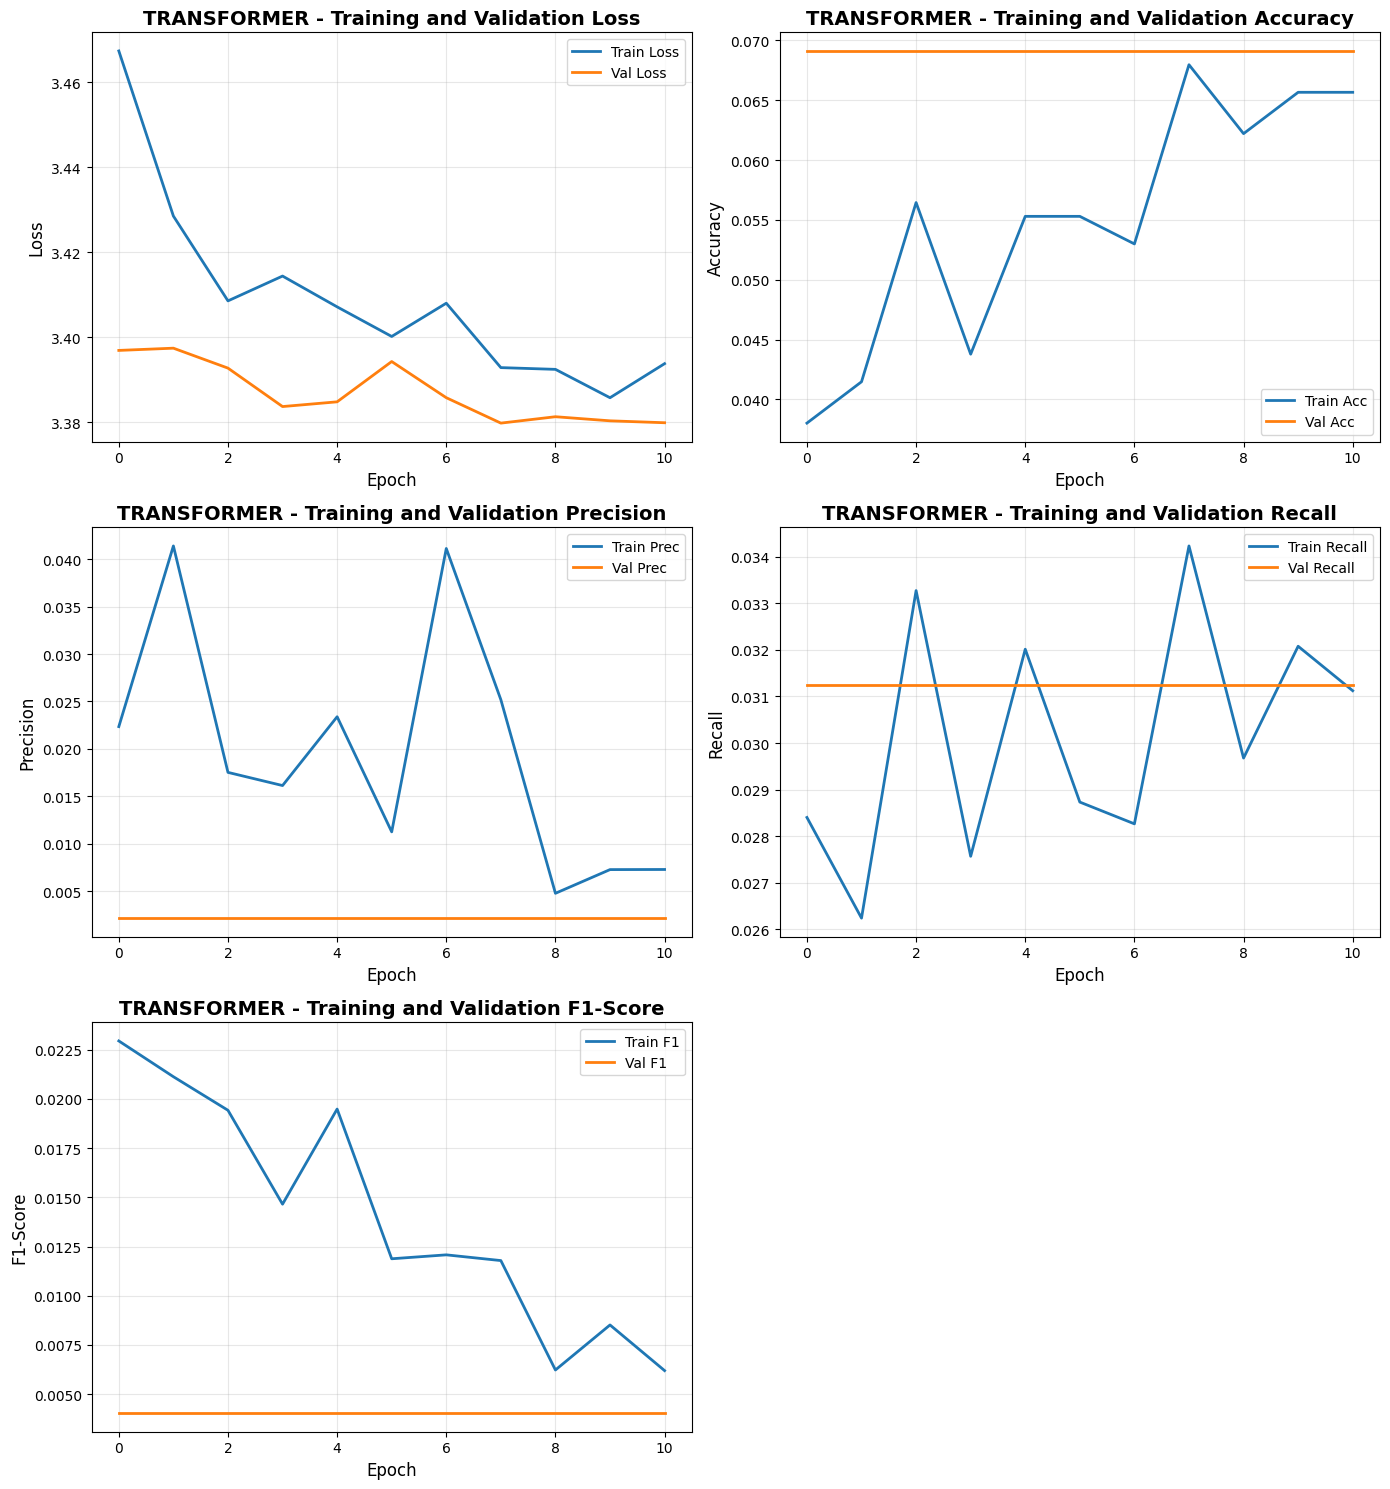

In [ ]:
# Plot training curves
fig, axes = plt.subplots(3, 2, figsize=(14, 15))
axes = axes.flatten()

# Loss
axes[0].plot(history['train_loss'], label='Train Loss', linewidth=2)
axes[0].plot(history['val_loss'], label='Val Loss', linewidth=2)
axes[0].set_xlabel('Epoch', fontsize=12)
axes[0].set_ylabel('Loss', fontsize=12)
axes[0].set_title(f'{MODEL_TYPE.upper()} - Training and Validation Loss', fontsize=14, fontweight='bold')
axes[0].legend(fontsize=10)
axes[0].grid(True, alpha=0.3)

# Accuracy
axes[1].plot(history['train_acc'], label='Train Acc', linewidth=2)
axes[1].plot(history['val_acc'], label='Val Acc', linewidth=2)
axes[1].set_xlabel('Epoch', fontsize=12)
axes[1].set_ylabel('Accuracy', fontsize=12)
axes[1].set_title(f'{MODEL_TYPE.upper()} - Training and Validation Accuracy', fontsize=14, fontweight='bold')
axes[1].legend(fontsize=10)
axes[1].grid(True, alpha=0.3)


# Precision
axes[2].plot(history['train_precision'], label='Train Prec', linewidth=2)
axes[2].plot(history['val_precision'], label='Val Prec', linewidth=2)
axes[2].set_xlabel('Epoch', fontsize=12)
axes[2].set_ylabel('Precision', fontsize=12)
axes[2].set_title(f'{MODEL_TYPE.upper()} - Training and Validation Precision', fontsize=14, fontweight='bold')
axes[2].legend(fontsize=10)
axes[2].grid(True, alpha=0.3)

# Recall
axes[3].plot(history['train_recall'], label='Train Recall', linewidth=2)
axes[3].plot(history['val_recall'], label='Val Recall', linewidth=2)
axes[3].set_xlabel('Epoch', fontsize=12)
axes[3].set_ylabel('Recall', fontsize=12)
axes[3].set_title(f'{MODEL_TYPE.upper()} - Training and Validation Recall', fontsize=14, fontweight='bold')
axes[3].legend(fontsize=10)
axes[3].grid(True, alpha=0.3)

# F1-Score
axes[4].plot(history['train_f1'], label='Train F1', linewidth=2)
axes[4].plot(history['val_f1'], label='Val F1', linewidth=2)
axes[4].set_xlabel('Epoch', fontsize=12)
axes[4].set_ylabel('F1-Score', fontsize=12)
axes[4].set_title(f'{MODEL_TYPE.upper()} - Training and Validation F1-Score', fontsize=14, fontweight='bold')
axes[4].legend(fontsize=10)
axes[4].grid(True, alpha=0.3)

# Hide the unused 6th subplot if necessary
if len(axes) > 5:
    fig.delaxes(axes[5])

plt.tight_layout()
plt.show()

In [ ]:
from sklearn.metrics import recall_score, f1_score, precision_score, accuracy_score
import numpy as np
import torch
from tqdm import tqdm

# Evaluate on test set
model.eval()
y_true = []
y_pred = []

with torch.no_grad():
    for inputs, labels in tqdm(test_loader, desc="Testing"):
        inputs = inputs.to(device)
        outputs = model(inputs)
        _, predicted = torch.max(outputs, 1)

        y_true.extend(labels.numpy())
        y_pred.extend(predicted.cpu().numpy())

y_true = np.array(y_true)
y_pred = np.array(y_pred)

# Calculate accuracy, recall, f1-score, and precision
test_accuracy = accuracy_score(y_true, y_pred)
calculated_recall_score = recall_score(y_true, y_pred, average='weighted')
calculated_f1_score = f1_score(y_true, y_pred, average='weighted')
calculated_precision_score = precision_score(y_true, y_pred, average='weighted')
print(f"\n{'='*60}")
print(f"{MODEL_TYPE.upper()} Model - Test Results")
print(f"{'='*60}")
print(f"Test Accuracy: {test_accuracy:.4f} ({test_accuracy*100:.2f}%)")
print(f"Recall: {calculated_recall_score:.4f}")
print(f"Precision: {calculated_precision_score:.4f}")
print(f"F1 Score: {calculated_f1_score:.4f}")

Testing: 100%|██████████| 17/17 [00:00<00:00, 91.86it/s]


TRANSFORMER Model - Test Results
Test Accuracy: 0.0368 (3.68%)
Recall: 0.0368
Precision: 0.0014
F1 Score: 0.0026


In [ ]:
# Classification report - FIXED: use labels parameter to handle missing classes
print("\nClassification Report:")
print("="*60)

# Get all possible labels
all_labels = list(range(len(label_encoder.classes_)))

print(classification_report(
    y_true,
    y_pred,
    labels=all_labels,
    target_names=label_encoder.classes_,
    digits=4,
    zero_division=0  # Handle classes with no predictions
))


Classification Report:
                                  precision    recall  f1-score   support

        Atlantic_Spotted_Dolphin     0.0000    0.0000    0.0000         9
                    Bearded_Seal     0.0000    0.0000    0.0000         6
             Beluga,_White_Whale     0.0000    0.0000    0.0000         8
              Bottlenose_Dolphin     0.0000    0.0000    0.0000         4
                   Bowhead_Whale     0.0368    1.0000    0.0709        10
                 Clymene_Dolphin     0.0000    0.0000    0.0000        10
                  Common_Dolphin     0.0000    0.0000    0.0000         8
              False_Killer_Whale     0.0000    0.0000    0.0000         9
              Fin,_Finback_Whale     0.0000    0.0000    0.0000         8
                 Frasers_Dolphin     0.0000    0.0000    0.0000        14
         Grampus,_Rissos_Dolphin     0.0000    0.0000    0.0000        11
                       Harp_Seal     0.0000    0.0000    0.0000         8
             

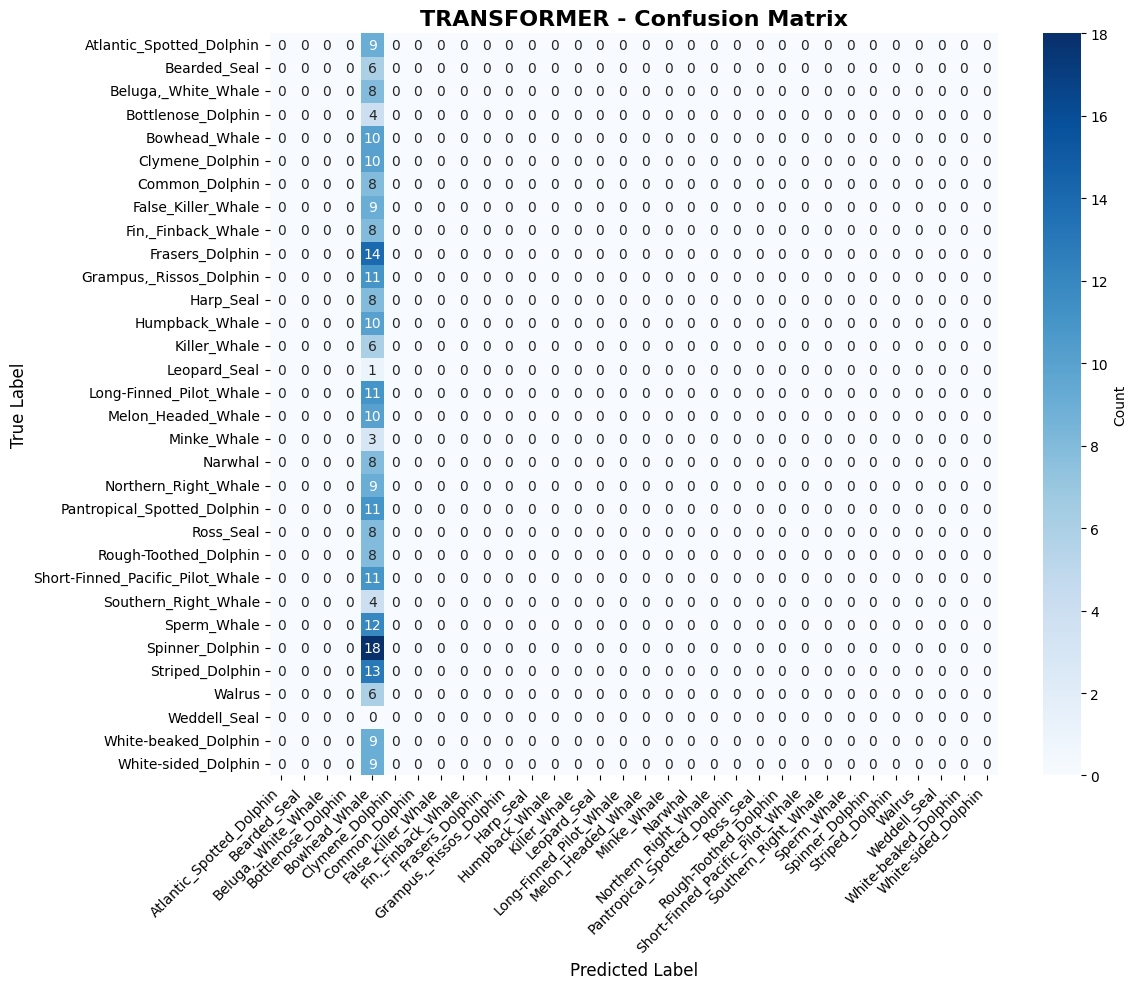

In [ ]:
# Confusion matrix
cm = confusion_matrix(y_true, y_pred, labels=all_labels)

plt.figure(figsize=(12, 10))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=label_encoder.classes_,
            yticklabels=label_encoder.classes_,
            cbar_kws={'label': 'Count'})
plt.title(f'{MODEL_TYPE.upper()} - Confusion Matrix', fontsize=16, fontweight='bold')
plt.ylabel('True Label', fontsize=12)
plt.xlabel('Predicted Label', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
def train_and_evaluate_model(model_type, num_classes, input_height, train_loader,
                              val_loader, test_loader, device, epochs=EPOCHS):
    """
    Train and evaluate a specific model type
    """
    print(f"\n{'#'*60}")
    print(f"# Training {model_type.upper()} Model")
    print(f"{'#'*60}")

    # Create model
    if model_type == 'dnn':
        model = WhaleDNN(num_classes, input_height).to(device)
    elif model_type == 'cnn':
        model = WhaleCNN(num_classes, input_size=input_height).to(device)
    elif model_type == 'rnn':
        model = WhaleRNN(num_classes, input_size=input_height).to(device)
    elif model_type == 'lstm':
        model = WhaleLSTM(num_classes, input_size=input_height).to(device)
    elif model_type == 'transformer':
        model = WhaleTransformer(num_classes, input_size=input_height).to(device)
    else:
        raise ValueError(f"Unknown model type: {model_type}")

    # Count parameters
    total_params = sum(p.numel() for p in model.parameters())
    print(f"Total parameters: {total_params:,}")

    # Setup training
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=5)

    # Train
    model, history = train_model(
        model, train_loader, val_loader, criterion, optimizer, scheduler,
        device, epochs, f'whale_{model_type}'
    )

    # Evaluate
    model.eval()
    y_true, y_pred = [], []

    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs = inputs.to(device)
            outputs = model(inputs)
            _, predicted = torch.max(outputs, 1)
            y_true.extend(labels.numpy())
            y_pred.extend(predicted.cpu().numpy())

    test_acc = accuracy_score(y_true, y_pred)
    print(f"\n{model_type.upper()} Test Accuracy: {test_acc:.4f} ({test_acc*100:.2f}%)")

    return {
        'model': model,
        'history': history,
        'test_acc': test_acc,
        'params': total_params
    }

In [ ]:
# Uncomment to train all models and compare
# WARNING: This will take a long time!

# results = {}
# for model_type in ['cnn', 'lstm', 'transformer']:
#     results[model_type] = train_and_evaluate_model(
#         model_type, num_classes, input_height,
#         train_loader, val_loader, test_loader, device, epochs=30
#     )

# # Compare results
# print("\n" + "="*60)
# print("MODEL COMPARISON")
# print("="*60)
# for model_type, res in results.items():
#     print(f"{model_type.upper():12s} | Acc: {res['test_acc']:.4f} | Params: {res['params']:,}")

In [ ]:
# Save the trained model
torch.save(model.state_dict(), f'{model_name}_classifier.pth')
print(f"Model saved to '{model_name}_classifier.pth'")

# Save complete model (architecture + weights)
torch.save(model, f'{model_name}_classifier_full.pth')
print(f"Full model saved to '{model_name}_classifier_full.pth'")

# Save label encoder
import pickle
with open('label_encoder.pkl', 'wb') as f:
    pickle.dump(label_encoder, f)
print("Label encoder saved to 'label_encoder.pkl'")

# Save training history
history_df = pd.DataFrame(history)
history_df.to_csv(f'{model_name}_training_history.csv', index=False)
print(f"Training history saved to '{model_name}_training_history.csv'")

print("\nAll artifacts saved successfully!")

Model saved to 'whale_transformer_classifier.pth'
Full model saved to 'whale_transformer_classifier_full.pth'
Label encoder saved to 'label_encoder.pkl'
Training history saved to 'whale_transformer_training_history.csv'

All artifacts saved successfully!


In [ ]:
def predict_audio(audio_path, model, label_encoder, device):
    """
    Predict class for a single audio file

    Args:
        audio_path: Path to audio file
        model: Trained model
        label_encoder: Label encoder
        device: torch device

    Returns:
        predicted_class: Predicted class name
        probabilities: Probability distribution
        confidence: Confidence score
    """
    model.eval()

    # Convert to spectrogram
    spec = audio_to_spectrogram(audio_path)

    if spec is None:
        return None, None, None

    # Add batch and channel dimensions
    spec = torch.FloatTensor(spec[np.newaxis, np.newaxis, :, :]).to(device)

    # Predict
    with torch.no_grad():
        outputs = model(spec)
        probabilities = F.softmax(outputs, dim=1).cpu().numpy()[0]

    predicted_idx = np.argmax(probabilities)
    predicted_class = label_encoder.inverse_transform([predicted_idx])[0]
    confidence = probabilities[predicted_idx]

    return predicted_class, probabilities, confidence

print("Prediction function defined!")

Prediction function defined!


SAMPLE PREDICTION
True Label: Bearded_Seal
Predicted Label: Bowhead_Whale
Confidence: 0.0375 (3.75%)

Correct: No


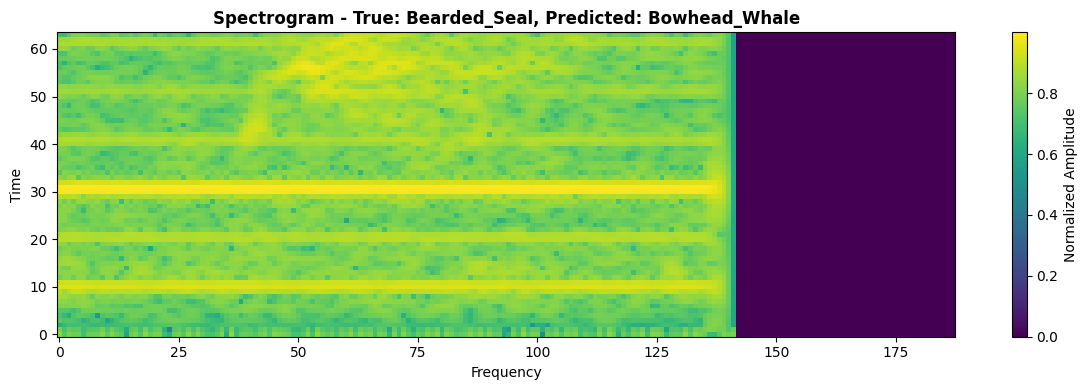

In [ ]:
# Example: Predict on a random test sample
test_idx = np.random.randint(0, len(X_test))
test_sample = torch.FloatTensor(X_test[test_idx:test_idx+1]).to(device)
true_label = label_encoder.inverse_transform([y_test[test_idx]])[0]

# Make prediction
model.eval()
with torch.no_grad():
    outputs = model(test_sample)
    pred_proba = F.softmax(outputs, dim=1).cpu().numpy()[0]

pred_idx = np.argmax(pred_proba)
pred_label = label_encoder.inverse_transform([pred_idx])[0]
confidence = pred_proba[pred_idx]

# Display results
print(f"{'='*60}")
print("SAMPLE PREDICTION")
print(f"{'='*60}")
print(f"True Label: {true_label}")
print(f"Predicted Label: {pred_label}")
print(f"Confidence: {confidence:.4f} ({confidence*100:.2f}%)")
print(f"\nCorrect: {'Yes' if true_label == pred_label else 'No'}")

# Visualize the spectrogram
plt.figure(figsize=(12, 4))
plt.imshow(X_test[test_idx, 0], aspect='auto', origin='lower', cmap='viridis')
plt.colorbar(label='Normalized Amplitude')
plt.title(f'Spectrogram - True: {true_label}, Predicted: {pred_label}', fontweight='bold')
plt.xlabel('Frequency')
plt.ylabel('Time')
plt.tight_layout()
plt.show()

In [ ]:
print("="*60)
print("WHALE AUDIO CLASSIFICATION - SUMMARY")
print("="*60)
print(f"\nDataset:")
print(f"  Total samples: {len(X)}")
print(f"  Number of classes: {num_classes}")
print(f"\nSpectrogram Processing:")
print(f"  Method: scipy.signal.spectrogram")
print(f"  FFT size: {N_FFT}")
print(f"  Hop length: {HOP_LENGTH}")
print(f"  Frequency bins: {N_FREQ_BINS}")
print(f"\nModel: {MODEL_TYPE.upper()}")
print(f"  Input shape: {X_train.shape[1:]}")
print(f"  Parameters: {total_params:,}")
print(f"\nPerformance:")
print(f"  Test Accuracy: {test_accuracy:.4f} ({test_accuracy*100:.2f}%)")
print(f"  Recall: {calculated_recall_score:.4f}")
print(f"  Precision: {calculated_precision_score:.4f}")
print(f"  F1 Score: {calculated_f1_score:.4f}")
print(f"\nAvailable Models:")
print(f"  - DNN (WhaleDNN)")
print(f"  - CNN (WhaleCNN)")
print(f"  - RNN (Whale RNN)")
print(f"  - LSTM (WhaleLSTM) with attention")
print(f"  - Transformer (WhaleTransformer) with CLS token")
print("="*60)
print("\nTraining Complete!")

WHALE AUDIO CLASSIFICATION - SUMMARY

Dataset:
  Total samples: 1357
  Number of classes: 32

Spectrogram Processing:
  Method: scipy.signal.spectrogram
  FFT size: 2048
  Hop length: 256
  Frequency bins: 64

Model: TRANSFORMER
  Input shape: (1, 64, 188)
  Parameters: 2,228,640

Performance:
  Test Accuracy: 0.0368 (3.68%)
  Recall: 0.0368
  Precision: 0.0014
  F1 Score: 0.0026

Available Models:
  - DNN (WhaleDNN)
  - CNN (WhaleCNN)
  - RNN (Whale RNN)
  - LSTM (WhaleLSTM) with attention
  - Transformer (WhaleTransformer) with CLS token

Training Complete!


Final Thoughts

Based on all of the models we have trained, the Transformer model is the best model to use despite having the second most amount of trainable parameters. The Transformer model has a test accuracy of 3.68 %, a recall score of 3.68 %, a precision score of 0.14 %, and a f1-score of 0.26 %.
